In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from sklearn.model_selection import train_test_split

train = pd.read_csv('train-2.csv')

main_titles = ['Mr', 'Miss', 'Mrs', 'Master']
train['Sex_coding'] = train['Sex'].map({'male': 1, 'female': 0})
train['family_size'] = train['SibSp'] + train['Parch'] + 1
train['Embarked'] = train['Embarked'].fillna('S')

train['Title'] = train['Name'].str.split(', ').str[1].str.split('.').str[0]
train['Title'] = train['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
train['Title'] = train['Title'].where(train['Title'].isin(main_titles), 'Rare')

train = pd.get_dummies(train, columns=['Embarked', 'Title'], dtype=int)

features_for_predict = ['Pclass', 'Sex_coding','Age','Fare', 'family_size','Embarked_C','Embarked_Q','Embarked_S','Title_Master',	'Title_Miss',	'Title_Mr',	'Title_Mrs',	'Title_Rare']
X,y = train[features_for_predict],train['Survived']


In [79]:


depths = [1, 2, 3, 4, 5, 6, 8, 10, 20]
train_value = []
test_value = []
for i in depths:
    pipeline = make_pipeline(SimpleImputer(strategy='median'), DecisionTreeClassifier(max_depth = i,random_state=42))
    cross_model= cross_validate(pipeline, X,y,cv = 5, return_train_score=True)
    print(cross_model['train_score'].mean())
    print(cross_model['test_score'].mean())
    print(i)
    train_value.append(cross_model['train_score'].mean())
    test_value.append(cross_model['test_score'].mean())
    print()

    

0.784230660132058
0.7788964911179461
1

0.8055537608144098
0.7834285355596007
2

0.8364187560080054
0.8226476680685456
3

0.847078730478907
0.8249011361496453
4

0.8619506122256017
0.8092272926997678
5

0.8801909166837385
0.8114242671520934
6

0.9074105299651732
0.7957378695624883
8

0.9379930504120901
0.7901387232439896
10

0.9840057046503932
0.7721674722239658
20



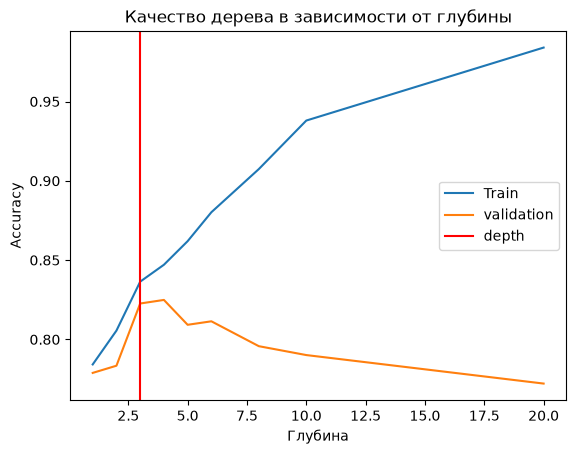

In [80]:
fig,ax = plt.subplots()
ax.plot(depths,np.array(train_value),label = 'Train')
ax.plot(depths,np.array(test_value),label = 'validation')
ax.set_title('Качество дерева в зависимости от глубины')
ax.set_xlabel('Глубина')
ax.axvline(3,label = 'depth',color = 'red')
ax.set_ylabel('Accuracy')
ax.legend()
plt.show()

## Вывод: глубина дерева решений (Titanic, 13 признаков, CV 5 фолдов)

| max_depth | Train accuracy | Validation accuracy | Разрыв |
|---|---|---|---|
| 1 | 0.784 | 0.779 | 0.005 |
| 2 | 0.806 | 0.783 | 0.022 |
| 3 | 0.836 | 0.823 | 0.014 |
| 4 | 0.847 | 0.825 | 0.022 |
| 5 | 0.862 | 0.809 | 0.053 |
| 6 | 0.880 | 0.811 | 0.069 |
| 8 | — | — | — |
| 10 | — | — | — |
| None | 0.984 | 0.772 | 0.212 |

На основе таблицы выбираю глубину 3, так как разница по validation с глубиной 4 (0.823 и 0.825) находится в пределах шума, а у глубины 3 разрыв между train и validation меньше (0.014 против 0.022) и дерево проще.

При росте глубины деревья начинают переобучаться: они уходят слишком глубоко и запоминают шум обучающих данных, поэтому accuracy на train растёт (до 0.984 без ограничения), а на validation падает (до 0.772), и разрыв увеличивается. На малой глубине (1 и 2) оба значения невысокие, это недообучение.

In [81]:
depths_rand = [3, 4, 5, 6, 8, None]
train_value_rand = []
test_value_rand = []
for i in depths:
    pipeline = make_pipeline(SimpleImputer(strategy='median'), RandomForestClassifier(max_depth = i,random_state=42,n_estimators=200))
    randforest_model= cross_validate(pipeline, X,y,cv = 5, return_train_score=True)
    print(randforest_model['train_score'].mean())
    print(randforest_model['test_score'].mean())
    print(i)
    train_value_rand.append(randforest_model['train_score'].mean())
    test_value_rand.append(randforest_model['test_score'].mean())
    print()


0.7870361031879856
0.7766806854560292
1

0.7951735033172069
0.793465570271797
2

0.8302452842082039
0.8192894356914191
3

0.8439975101249665
0.8305065595380077
4

0.854097656680902
0.827154604230745
5

0.8672853270718754
0.824913690289373
6

0.9197531399215217
0.8260435628648548
8

0.9438848354003498
0.8215617349821104
10

0.9840057046503932
0.8036155922415416
20



[0.11421673 0.24427024 0.04420289 0.0862971  0.06432485 0.01354217
 0.00651113 0.01091247 0.01306243 0.06640614 0.2538562  0.07540495
 0.00699269]
Title_Mr        0.253856
Sex_coding      0.244270
Pclass          0.114217
Fare            0.086297
Title_Mrs       0.075405
Title_Miss      0.066406
family_size     0.064325
Age             0.044203
Embarked_C      0.013542
Title_Master    0.013062
Embarked_S      0.010912
Title_Rare      0.006993
Embarked_Q      0.006511
dtype: float64


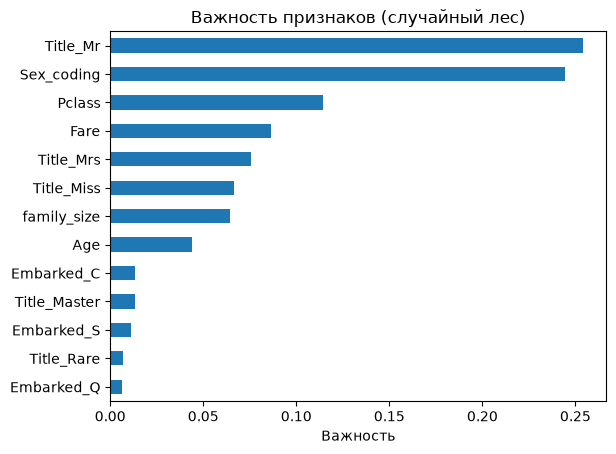

In [82]:

pipeline = make_pipeline(SimpleImputer(strategy='median'), RandomForestClassifier(n_estimators=200, random_state=42,max_depth= 4))

forest_rand = pipeline.fit(X,y)


importances = pipeline[-1].feature_importances_
print(importances)

imp = pd.Series(importances, index=features_for_predict).sort_values(ascending=False)
print(imp)

fig, ax = plt.subplots()
imp.sort_values().plot(kind='barh', ax=ax)
ax.set_xlabel('Важность')
ax.set_title('Важность признаков (случайный лес)')
plt.show()

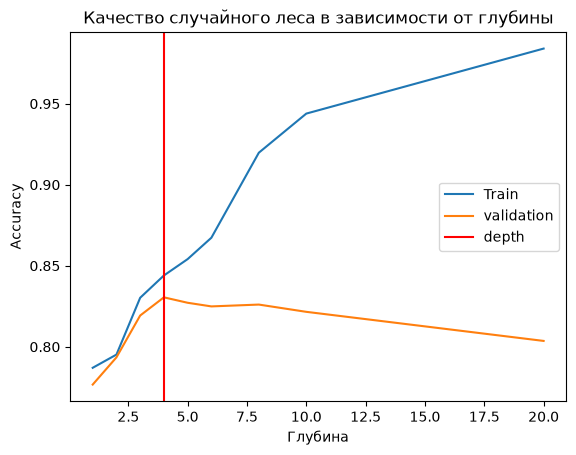

In [83]:
fig,ax = plt.subplots()
ax.plot(depths,np.array(train_value_rand),label = 'Train')
ax.plot(depths,np.array(test_value_rand),label = 'validation')
ax.set_title('Качество случайного леса в зависимости от глубины')
ax.set_xlabel('Глубина')
ax.axvline(4,label = 'depth',color = 'red')
ax.set_ylabel('Accuracy')
ax.legend()
plt.show()

## Вывод: случайный лес (Titanic, 13 признаков, CV 5 фолдов, accuracy)

| max_depth | Train | Validation | Разрыв |
|---|---|---|---|
| 1 | 0.787 | 0.776 | 0.011 |
| 2 | 0.804 | 0.796 | 0.008 |
| 3 | 0.833 | 0.822 | 0.011 |
| 4 | 0.843 | 0.831 | 0.012 |
| 5 | 0.852 | 0.825 | 0.027 |
| 6 | 0.867 | 0.823 | 0.044 |
| 8 | — | — | — |
| 10 | — | — | — |
| None (20) | 0.984 | 0.805 | 0.179 |

Сравнение моделей по CV-accuracy (лучшая глубина или лучший вариант):

| Модель | CV-accuracy |
|---|---|
| Логистическая регрессия | 0.827 |
| Дерево решений (max_depth = 4) | 0.825 |
| Случайный лес (max_depth = 4) | 0.831 |

Лучшая глубина случайного леса равна 4. При большой глубине лес переобучается заметно слабее одного дерева: без ограничения validation 0.805 против 0.772 у дерева, а при глубинах 3–6 качество леса почти не меняется (0.82–0.83). На лучшей глубине лес (0.831) лишь немного обгоняет дерево (0.825) и логистическую регрессию (0.827), разница в пределах шума.

### Важность признаков (случайный лес, max_depth = 4)

| Признак | Важность |
|---|---|
| Title_Mr | 0.254 |
| Sex_coding | 0.244 |
| Pclass | 0.114 |
| Fare | 0.086 |
| Title_Mrs | 0.075 |
| Title_Miss | 0.066 |
| family_size | 0.064 |
| Age | 0.044 |
| Embarked_C | 0.014 |
| Title_Master | 0.013 |
| Embarked_S | 0.011 |
| Title_Rare | 0.007 |
| Embarked_Q | 0.007 |

Наиболее важные признаки это титул и пол, что совпадает с логистической регрессией (там тоже самый сильный вес у пола). Далее идут класс билета и стоимость билета. Порт посадки почти не влияет.

In [84]:
test = pd.read_csv('test-2.csv')
new_features_for_predict1 = ['Pclass', 'Sex_coding','Age','Fare', 'family_size','Embarked_C','Embarked_Q','Embarked_S','Title_Master',	'Title_Miss',	'Title_Mr',	'Title_Mrs',	'Title_Rare']
test['Sex_coding'] = test['Sex'].map({'male': 1, 'female': 0})
test['family_size'] = test['SibSp'] + test['Parch'] + 1
test['Embarked'] = test['Embarked'].fillna('S')

test['Title'] = test['Name'].str.split(', ').str[1].str.split('.').str[0]
test['Title'] = test['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
test['Title'] = test['Title'].where(test['Title'].isin(main_titles), 'Rare')

test = pd.get_dummies(test, columns=['Embarked', 'Title'], dtype=int)

# 3. Те же 13 признаков в том же порядке
X_test_final = test.reindex(columns=new_features_for_predict1, fill_value=0)
print(X_test_final.shape)         # (418, 13)
print(X_test_final.isna().sum())  # пропуски только в Age и Fare
test['Survived'] = pipeline.predict(X_test_final)
test[['PassengerId', 'Survived']].to_csv('submission.csv', index=False)

# 5. Проверка
submission = pd.read_csv('submission.csv')
print(submission.shape)
print(submission['Survived'].value_counts())
print(submission['PassengerId'].min(), submission['PassengerId'].max())



(418, 13)
Pclass           0
Sex_coding       0
Age             86
Fare             1
family_size      0
Embarked_C       0
Embarked_Q       0
Embarked_S       0
Title_Master     0
Title_Miss       0
Title_Mr         0
Title_Mrs        0
Title_Rare       0
dtype: int64
(418, 2)
Survived
0    257
1    161
Name: count, dtype: int64
892 1309
